<a href="https://colab.research.google.com/github/Xyrfo/PCVK26_24_Rifo/blob/main/P2_Tugas_D1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2 as cv
from google.colab.patches import cv2_imshow
from skimage import io
import matplotlib.pyplot as plt
import numpy as np

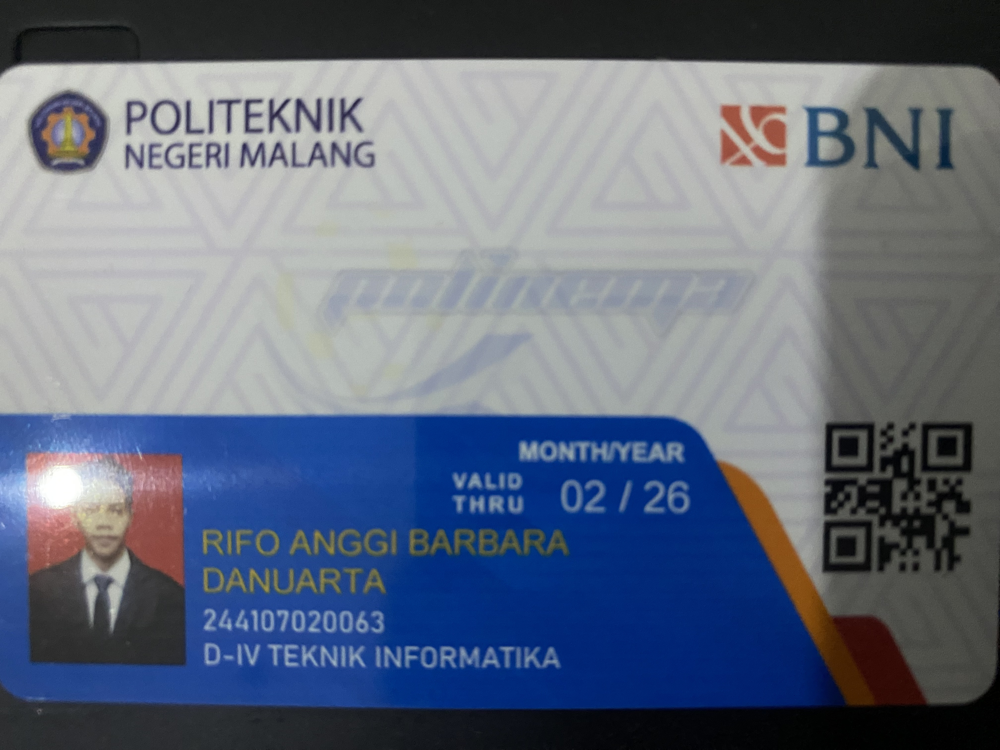

In [9]:
img = cv.imread("/content/drive/MyDrive/PCVK 2026/Ktm.jpg")
cv2_imshow(img)

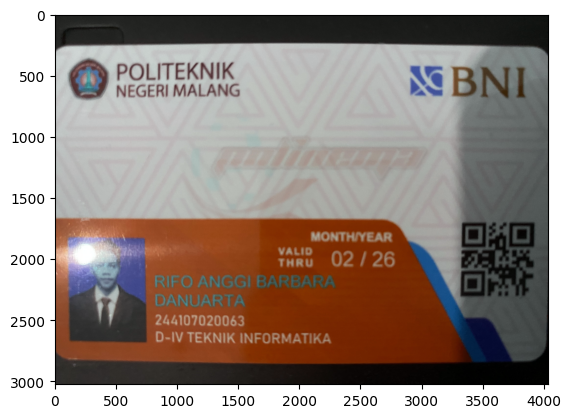

In [10]:
img = cv.imread("/content/drive/MyDrive/PCVK 2026/Ktm.jpg")
plt.imshow(img)

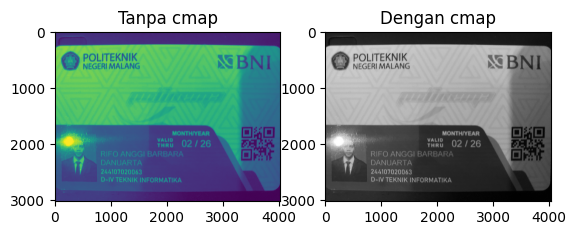

In [13]:
img_gray = cv.imread("/content/drive/MyDrive/PCVK 2026/Ktm.jpg", cv.IMREAD_GRAYSCALE)
#Tanpa cmap
plt.subplot(1,2,1)
plt.imshow(img_gray)
plt.title('Tanpa cmap')

#Dengan cmap
plt.subplot(1,2,2)
plt.imshow(img_gray, cmap='gray')
plt.title('Dengan cmap')

plt.show()



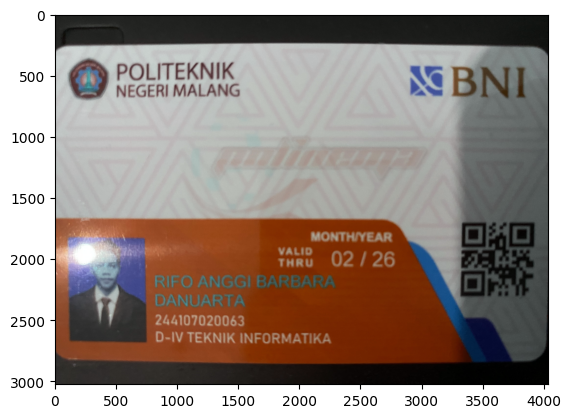

In [14]:
img_gray = cv.imread("/content/drive/MyDrive/PCVK 2026/Ktm.jpg")
plt.imshow(img_gray, cmap='magma')
plt.show()

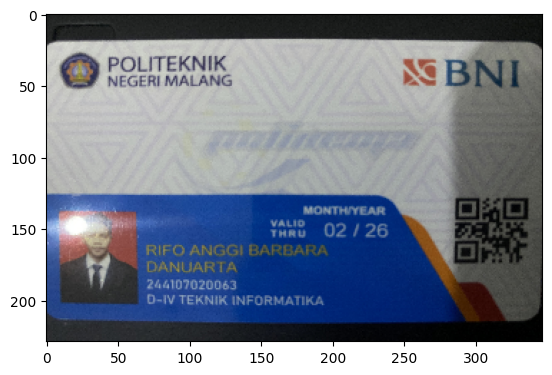

In [15]:
imgRGB = cv.imread("/content/drive/MyDrive/PCVK 2026/Ktm.jpg")

imgRGB = cv.cvtColor(imgRGB, cv.COLOR_BGR2RGB)
img_output = (cv.resize(imgRGB, (347,229)))
plt.imshow(img_output)

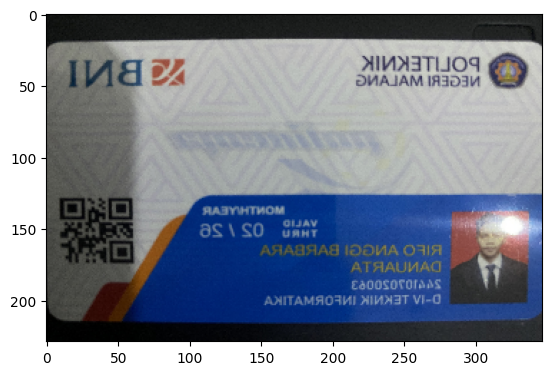

In [16]:
imgflip = cv.flip(img_output, 1)
plt.imshow(imgflip)

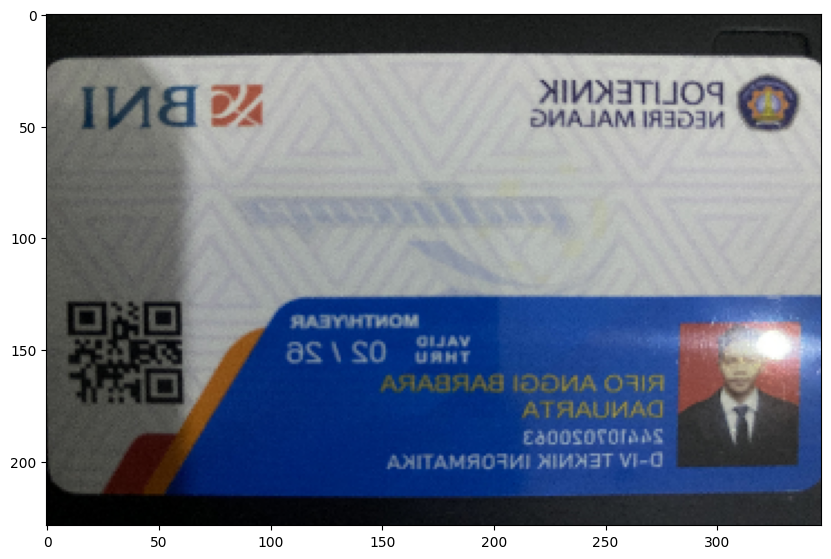

In [17]:
imgFlip=cv.flip(img_output, 1)

fig = plt.figure(figsize= (10,10))
ax=fig.add_subplot(1,1,1)
ax.imshow(imgFlip)

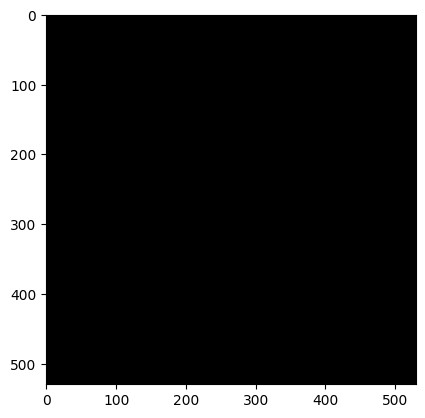

In [18]:
black_img=np.zeros(shape=(530,530,3),dtype=np.int16)
plt.imshow(black_img)

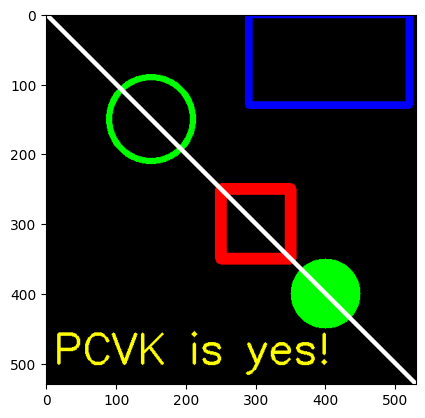

In [19]:
cv.rectangle(black_img,pt1=(290,0),pt2=(520,130),color=(0,0,255),thickness=10)
cv.rectangle(black_img,pt1=(250,250),pt2=(350,350),color=(255,0,0),thickness=15)
cv.circle(black_img,center=(150,150),radius=60,color=(0,255,0),thickness=8)
cv.circle(black_img,center=(400,400),radius=50,color=(0,255,0),thickness=-1)
cv.line(black_img,pt1=(0,0),pt2=(530,530),color=(255,255,255),thickness=5)

font = cv.FONT_HERSHEY_SIMPLEX
cv.putText(black_img,text='PCVK is yes!',org=(10,500),fontFace=font,fontScale=2,color=(255,255,0),thickness=3,lineType=cv.LINE_AA)
plt.imshow(black_img)

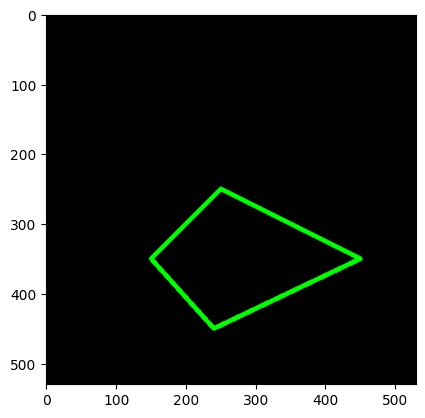

In [20]:
black_img2=np.zeros(shape=(530,530,3),dtype=np.int32)
vertices = np.array([[150,350],[250,250],[450,350],[240,450]],np.int32)
vertices

pts = vertices.reshape((-1,1,2))
plt.imshow(black_img2)


cv.polylines(black_img2,[pts],isClosed=True,color=(0,255,0),thickness=5)
plt.imshow(black_img2)

# **PERTANYAAN PRAKTIKUM**

Jawab pertanyaan berikut pada sel Markdown di dalam notebook Anda. Setiap
jawaban yang menyebut nilai atau ukuran wajib disertai keluaran program.
1. Tampilkan satu citra bebas menggunakan cv2_imshow() dan plt.imshow()
tanpa konversi warna apa pun. Mengapa hasilnya berbeda? Buktikan dengan
mencetak nilai satu piksel yang sama dari kedua cara pembacaan tersebut.

jawab:

Keluaran visual dari kedua fungsi tersebut berbeda karena adanya perbedaan asumsi urutan kanal warna. OpenCV (cv2.imread) secara bawaan membaca citra dan menyimpannya dalam urutan matriks BGR (Blue, Green, Red). Fungsi cv2_imshow() dikembangkan khusus untuk membaca format BGR ini, sehingga warnanya tampil dengan benar. Sebaliknya, Matplotlib (plt.imshow) mengasumsikan bahwa array yang dimasukkan memiliki urutan RGB. Jika citra BGR langsung diplot ke Matplotlib tanpa konversi, piksel Biru dan Merah akan tertukar posisinya, menghasilkan gambar dengan warna kebiruan.


Tampilan menggunakan cv2_imshow:


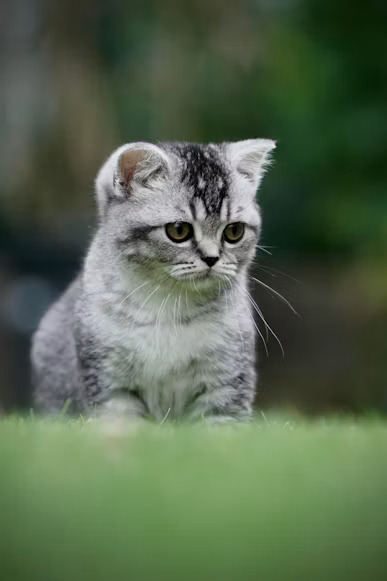


Tampilan menggunakan plt.imshow:


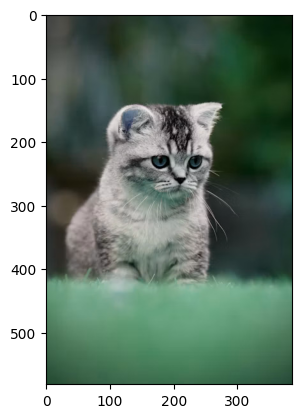


Nilai piksel mentah pada koordinat [0,0] (Urutan BGR): [67 68 66]


In [22]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread('/content/drive/MyDrive/PCVK 2026/cat_test.jpg')

print("Tampilan menggunakan cv2_imshow:")
cv2_imshow(img)

print("\nTampilan menggunakan plt.imshow:")
plt.imshow(img)
plt.show()

print("\nNilai piksel mentah pada koordinat [0,0] (Urutan BGR):", img[0,0])

2. Buat kanvas hitam berukuran sama dengan tipe data int16 dan int32.
Bandingkan dtype, min(), max(), dan nbytes keduanya. Apakah tampilannya
berbeda? Apakah ukuran memorinya berbeda? Jelaskan alasannya.

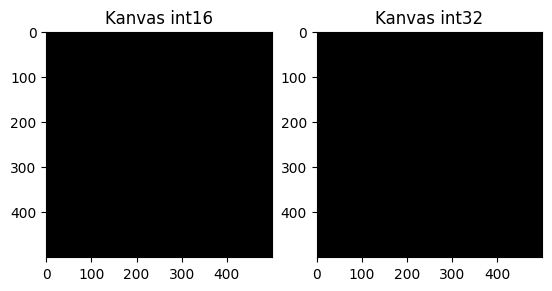


Perbandingan Properti:
INT16 -> dtype: int16 | min: 0 | max: 0 | nbytes: 1500000
INT32 -> dtype: int32 | min: 0 | max: 0 | nbytes: 3000000


In [25]:
import numpy as np
import matplotlib.pyplot as plt

img_16 = np.zeros((500, 500, 3), dtype=np.int16)
img_32 = np.zeros((500, 500, 3), dtype=np.int32)

plt.subplot(1, 2, 1)
plt.imshow(img_16)
plt.title("Kanvas int16")

plt.subplot(1, 2, 2)
plt.imshow(img_32)
plt.title("Kanvas int32")
plt.show()

print("\nPerbandingan Properti:")
print("INT16 -> dtype:", img_16.dtype, "| min:", img_16.min(), "| max:", img_16.max(), "| nbytes:", img_16.nbytes)
print("INT32 -> dtype:", img_32.dtype, "| min:", img_32.min(), "| max:", img_32.max(), "| nbytes:", img_32.nbytes)

3. Apa kegunaan baris from google.colab.patches import cv2_imshow, dan
mengapa cv2.imshow() bawaan OpenCV tidak dapat dipakai di Google Colab?

jawab:

Fungsi bawaan cv2.imshow() dirancang untuk meminta sistem operasi (seperti Windows atau Linux) membuka jendela antarmuka grafis (GUI) baru untuk merender gambar. Google Colab beroperasi di atas lingkungan cloud berbasis antarmuka web browser yang tidak memiliki kapabilitas untuk memicu jendela GUI sistem operasi secara lokal. Oleh karena itu, modul google.colab.patches menyediakan fungsi pengganti cv2_imshow() yang telah dimodifikasi agar dapat merender array citra secara langsung sebagai output cell berformat HTML/gambar di dalam browser.

4. Citra yang dibaca dengan skimage.io.imread() ditampilkan berdampingan
dengan hasil cv2.cvtColor(img, cv2.COLOR_BGR2RGB) atas citra yang
sama. Manakah yang menampilkan warna sebenarnya, dan manakah yang
kanalnya tertukar? Buktikan dengan nilai piksel, bukan dengan pengamatan
visual saja.

jawab:

Citra yang menampilkan warna sebenarnya adalah hasil dari skimage.io.imread(), karena pustaka ini sejak awal membaca citra dalam urutan RGB. Citra yang kanalnya tertukar adalah hasil dari cv2.cvtColor(img, cv2.COLOR_BGR2RGB).  Menerapkan fungsi konversi BGR ke RGB pada gambar yang sudah berformat RGB justru akan membalik urutan kanal Merah (indeks 0) dan Biru (indeks 2) yang semula sudah benar menjadi format BGR. Hal ini dibuktikan dari output nilai piksel yang dicetak, di mana angka pertama dan ketiga dari array tersebut saling bertukar posisi.

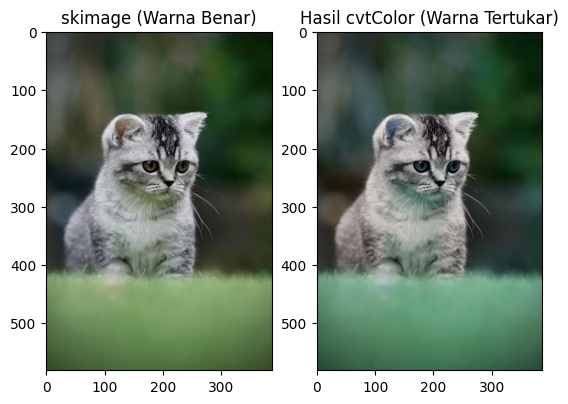

Nilai piksel asli skimage (RGB) : [66 68 67]
Nilai piksel setelah cvtColor   : [67 68 66]


In [26]:
from skimage import io
import cv2
import matplotlib.pyplot as plt

img_skimage = io.imread('/content/drive/MyDrive/PCVK 2026/cat_test.jpg')

img_tertukar = cv2.cvtColor(img_skimage, cv2.COLOR_BGR2RGB)

plt.subplot(1, 2, 1)
plt.imshow(img_skimage)
plt.title("skimage (Warna Benar)")

plt.subplot(1, 2, 2)
plt.imshow(img_tertukar)
plt.title("Hasil cvtColor (Warna Tertukar)")
plt.show()

print("Nilai piksel asli skimage (RGB) :", img_skimage[0,0])
print("Nilai piksel setelah cvtColor   :", img_tertukar[0,0])

5. Setelah citra ditampilkan dengan figsize yang jauh lebih besar, apakah nilai
img.shape ikut berubah? Jelaskan perbedaan antara mengubah ukuran citra
dan mengubah ukuran tampilan.

jawab:

Mengubah ukuran tampilan (figsize): Hanya memperbesar bingkai atau kanvas gambar di layar, tanpa mengubah data piksel di dalam matriks aslinya.  Mengubah ukuran citra (cv2.resize()): Benar-benar mengubah jumlah piksel dan struktur matriks data citra secara permanen.

# **TUGAS PRAKTIKUM - Penerapan**

Berdasarkan praktikum bagian 1 dan 2 kerjakan beberapa tugas berikut :

1. Tampilkan citra hanya pada kombinasi kanal Merah-Biru dan kanal Hijau-
Biru saja, dengan kanal yang tidak dipakai dinolkan. Susun keduanya

berdampingan dalam satu figure yang diberi judul.


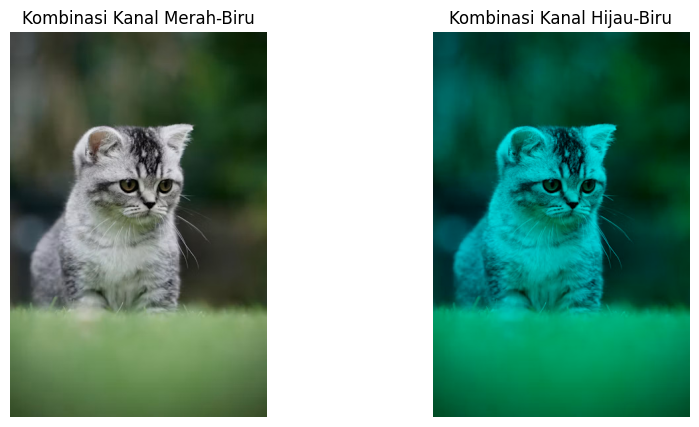

In [27]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

img = cv2.imread('/content/drive/MyDrive/PCVK 2026/cat_test.jpg')
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

img_rb = img_rgb.copy()
img_gb = img_rgb.copy()


img_gb[:, :, 0] = 0

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_rb)
plt.title("Kombinasi Kanal Merah-Biru")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_gb)
plt.title("Kombinasi Kanal Hijau-Biru")
plt.axis('off')

plt.show()

2. Tampilkan citra dalam tiga bentuk pencerminan: vertikal, horizontal, dan
keduanya, dalam satu figure berisi tiga subplot yang masing-masing diberi
label.

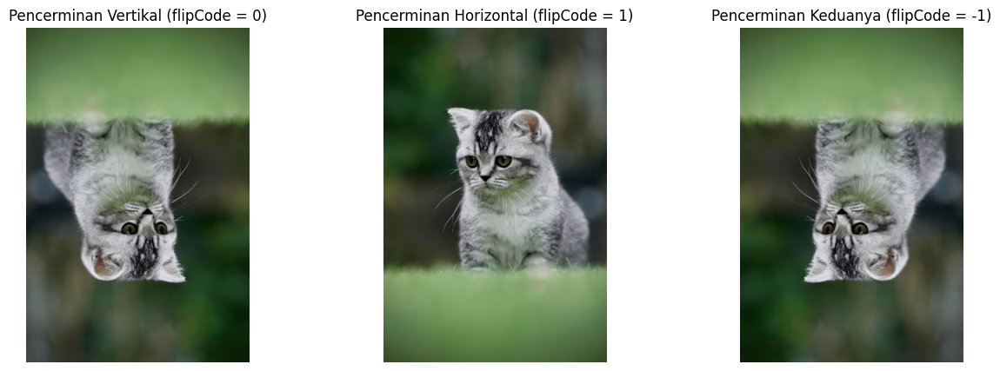

In [28]:
img = cv2.imread('/content/drive/MyDrive/PCVK 2026/cat_test.jpg')
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

flip_vertikal = cv2.flip(img_rgb, 0)
flip_horizontal = cv2.flip(img_rgb, 1)
flip_keduanya = cv2.flip(img_rgb, -1)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(flip_vertikal)
plt.title("Pencerminan Vertikal (flipCode = 0)")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(flip_horizontal)
plt.title("Pencerminan Horizontal (flipCode = 1)")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(flip_keduanya)
plt.title("Pencerminan Keduanya (flipCode = -1)")
plt.axis('off')

plt.show()

3. Gambarkan sebuah rectangle dan sebuah circle pada bagian wajah /
badan dari foto aktivitas Anda sendiri (bukan pasfoto), lalu tambahkan
teks berisi nama Anda dengan pilihan font, ukuran, dan warna yang Anda
tentukan sendiri.

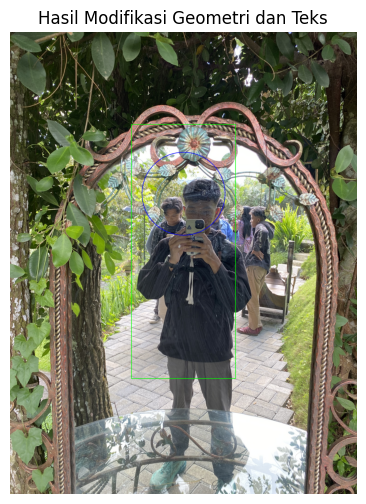

In [30]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

img_aktivitas = cv2.imread('/content/drive/MyDrive/PCVK 2026/Foto_prak.jpg')

img_hasil = img_aktivitas.copy()

tinggi, lebar, _ = img_hasil.shape

pt1 = (int(lebar * 0.35), int(tinggi * 0.20))
pt2 = (int(lebar * 0.65), int(tinggi * 0.75))
color_bgr_kotak = (0, 255, 0)
cv2.rectangle(img_hasil, pt1, pt2, color=color_bgr_kotak, thickness=3)

center_titik = (int(lebar * 0.50), int(tinggi * 0.35))
radius = int(lebar * 0.12)
color_bgr_lingkaran = (255, 0, 0)
cv2.circle(img_hasil, center=center_titik, radius=radius, color=color_bgr_lingkaran, thickness=3)

img_hasil_rgb = cv2.cvtColor(img_hasil, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6, 6))
plt.imshow(img_hasil_rgb)
plt.title("Hasil Modifikasi Geometri dan Teks")
plt.axis('off')
plt.show()

# **TUGAS PRAKTIKUM - Analisa**

1. Rumuskan satu pertanyaan tentang citra digital yang dapat Anda jawab
menggunakan kode dari modul ini. Contoh pertanyaan: berapa persen
piksel pada foto KTM Anda yang lebih gelap dari nilai 100? apakah
mengecilkan lalu membesarkan citra mengubah rata-rata intensitasnya?
Tuliskan pertanyaan Anda, rancangan program, data hasilnya, dan
kesimpulan Anda.

### **Pertanyaan Analisis**

Apakah mengecilkan lalu membesarkan citra kembali ke ukuran semula mengubah nilai rata-rata intensitas (keabuan) pikselnya?

### **Rancangan Program**

Program ini membaca citra dalam bentuk keabuan (grayscale), menghitung rata-rata intensitas awalnya, mengecilkan ukuran citra menggunakan fungsi cv2.resize(), membesarkannya kembali ke ukuran dimensi semula, lalu membandingkan rata-rata intensitas akhirnya.

Rata-rata intensitas awal  : 107.75091775714915
Rata-rata intensitas akhir : 107.8137620596078
Selisih nilai rata-rata    : 0.06284430245864314


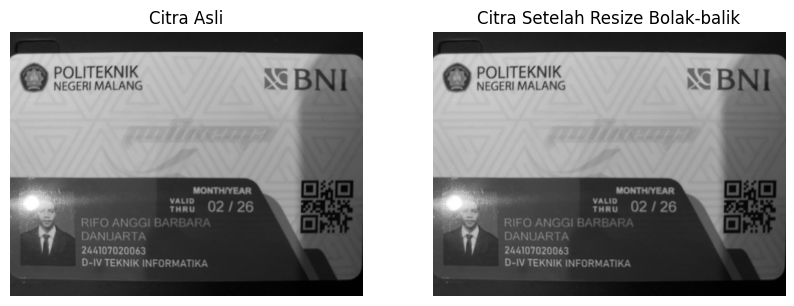

In [34]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('/content/drive/MyDrive/PCVK 2026/Ktm.jpg', cv2.IMREAD_GRAYSCALE)
tinggi, lebar = img.shape

rata_awal = np.mean(img)

img_kecil = cv2.resize(img, (int(lebar / 2), int(tinggi / 2)), interpolation=cv2.INTER_LINEAR)

img_kembali = cv2.resize(img_kecil, (lebar, tinggi), interpolation=cv2.INTER_LINEAR)

rata_akhir = np.mean(img_kembali)

print("Rata-rata intensitas awal  :", rata_awal)
print("Rata-rata intensitas akhir :", rata_akhir)
print("Selisih nilai rata-rata    :", abs(rata_awal - rata_akhir))

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title("Citra Asli")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_kembali, cmap='gray')
plt.title("Citra Setelah Resize Bolak-balik")
plt.axis('off')

plt.show()

### **Kesimpulan**

Mengecilkan lalu membesarkan citra kembali dapat mengubah nilai rata-rata intensitas pikselnya, meskipun perubahannya sangat kecil (mendekati nol).

# **TUGAS PRAKTIKUM - Aplikasi**

Studi Kasus 1: Panitia sebuah kegiatan perlu membubuhkan label identitas pada
ratusan foto dokumentasi. Foto berasal dari beberapa kamera dan ponsel,
sehingga ukurannya bermacam-macam. Label harus terlihat seimbang pada
semua foto tanpa disetel satu per satu. Fungsi yang sama dikenakan pada dua
citra berbeda ukuran. Tinggi bar dan ukuran huruf ikut menyesuaikan, sehingga
proporsinya tetap sama. Silakan melakukan akuisisi data sendiri, setiap anak
harus menggunakan image yang berbeda-beda

Ukuran Asli Gambar 1: 827 x 1476


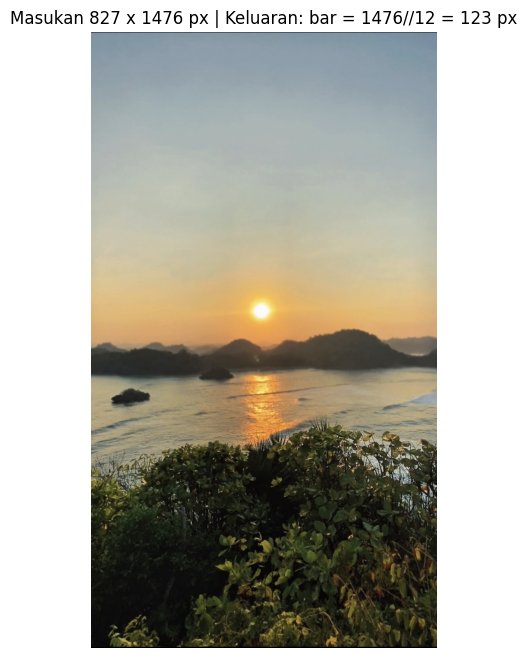

Ukuran Asli Gambar 2: 827 x 469


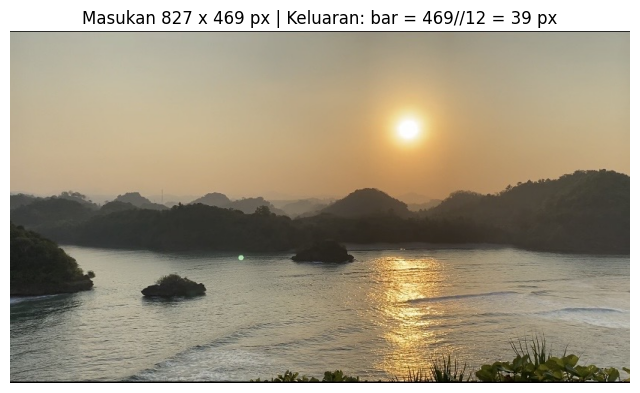

In [47]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

img1 = cv2.imread('/content/drive/MyDrive/PCVK 2026/Dokumentasi_Pcvk1.jpg')
img_rgb1 = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)

img2 = cv2.imread('/content/drive/MyDrive/PCVK 2026/Dokumentasi_Pcvk2.jpg')
img_rgb2 = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)

tinggi1, lebar1, _ = img_rgb1.shape
tinggi2, lebar2, _ = img_rgb2.shape

tinggi_bar1 = tinggi1 // 12
tinggi_bar2 = tinggi2 // 12

print("Ukuran Asli Gambar 1:", lebar1, "x", tinggi1)

final_output1 = cv2.vconcat([img_rgb1])

plt.figure(figsize=(8, 8))
plt.imshow(final_output1)
plt.title(f"Masukan {lebar1} x {tinggi1} px | Keluaran: bar = {tinggi1}//12 = {tinggi_bar1} px")
plt.axis('off')
plt.show()

print("Ukuran Asli Gambar 2:", lebar2, "x", tinggi2)

final_output2 = cv2.vconcat([img_rgb2])

plt.figure(figsize=(8, 8))
plt.imshow(final_output2)
plt.title(f"Masukan {lebar2} x {tinggi2} px | Keluaran: bar = {tinggi2}//12 = {tinggi_bar2} px")
plt.axis('off')
plt.show()

Studi Kasus 2: Marketplace seperti Tokopedia dan Shopee menampilkan foto
produk dalam bingkai persegi 1:1. Foto penjual yang berukuran potrait atau
lanskap akan terpotong atau terlihat tidak proporsional bila diunggah begitu saja.
Bangun program yang mengubah foto berukuran apa pun menjadi thumbnail
persegi tanpa mengubah rasio aslinya, dengan sisa ruang diisi kanvas berwarna.
Dalam hal ini, rasio asli tetap terjaga, citra terpasang tepat di tengah kanvas,
tambahkan logo nama toko berukuran proporsional pada gambar.

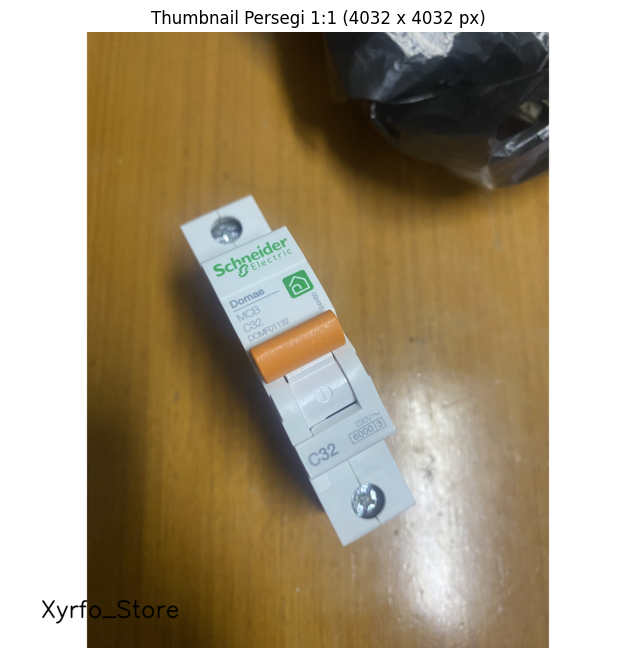

In [49]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

img = cv2.imread('/content/drive/MyDrive/PCVK 2026/Produk_Pcvk.jpg')
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

tinggi, lebar, _ = img_rgb.shape

ukuran_kanvas = max(tinggi, lebar)

kanvas_putih = np.full((ukuran_kanvas, ukuran_kanvas, 3), 255, dtype=np.uint8)

y_offset = (ukuran_kanvas - tinggi) // 2
x_offset = (ukuran_kanvas - lebar) // 2

kanvas_putih[y_offset:y_offset+tinggi, x_offset:x_offset+lebar] = img_rgb

teks_toko = "Xyrfo_Store"
skala_font = max(0.5, ukuran_kanvas / 800.0)
ketebalan_font = max(1, int(ukuran_kanvas / 400))
posisi_teks = (int(ukuran_kanvas * 0.05), int(ukuran_kanvas * 0.95))

cv2.putText(kanvas_putih, text=teks_toko, org=posisi_teks, fontFace=cv2.FONT_HERSHEY_SIMPLEX,
            fontScale=skala_font, color=(0, 0, 0), thickness=ketebalan_font, lineType=cv2.LINE_AA)

plt.figure(figsize=(8, 8))
plt.imshow(kanvas_putih)
plt.title(f"Thumbnail Persegi 1:1 ({ukuran_kanvas} x {ukuran_kanvas} px)")
plt.axis('off')
plt.show()